# 01. 피처 인사이트 EDA — 설명변수 × 종속변수

**목적**: 모델링 전에 금융·쇼핑·키워드·날씨 변수군이 Target과 어떤 관계인지 시각화로 확인하고, **파생변수·전처리·Feature Selection 방향**을 정한다.
(큰 틀: ① 검증 설계 → **② Feature Engineering ← 이 노트북** → ③ 모델·앙상블)

**원칙**
- ⚠️ **Train만 사용**한다. Test는 EDA에서도 보지 않는다 (Train-Test Contamination 방지, 자료 p.13·25).
- 모든 변환은 **과거 값만** 사용한다 (`shift(+n)`, `pct_change`, 과거 rolling). 미래 값 사용 = Target Leakage.
- 단일 변수 신호는 **AUC**로 잰다 (평가지표와 동일). `|AUC-0.5|`가 클수록 신호가 강하다. 0.5 미만은 반대 방향 신호.
- 신호가 진짜인지 보기 위해 Train을 **앞/뒤 절반**으로 나눠 두 구간에서 방향이 같은지 확인한다 (안정성).
- 참고: 자료의 공공(PU_, 월단위) 데이터는 이번 과제에서 제외되어 '산업' 지표는 없다 (p.20).

## 📖 이 노트북 읽는 법 (처음 보는 사람용)

**한 줄 요약**: 287개 변수를 6가지 형태로 바꿔 가며 "이 변수 하나만으로 Target을 얼마나 맞히나"를 재고, 그 신호가 **진짜인지(시간이 지나도 유지되는지)**, **새로운 정보인지(요일을 다시 말한 것뿐인지)** 를 확인한다.

**흐름** — 각 절은 앞 절의 의문에 답한다
| 절 | 질문 | 답 (요약) |
| --- | --- | --- |
| §1 | Target은 어떤 성질인가? | T2는 요일로 거의 결정, T1은 요일 무관·시기마다 출렁임 |
| §2 | 변수들은 어떤 상태인가? | 금융·쇼핑에 추세 → 원값보다 변화율·비율로 써야 함 |
| §3 | 어떤 변수·형태에 신호가 있나? | T1: 미국지수 변화율 + 쇼핑 '평소 대비'. T2: 수백 개가 신호 → 의심 |
| §4 | T2 신호의 정체는? | 요일별 클릭 패턴. 남은 과제는 애매한 요일 2·5 |
| §5 | 며칠 전 값이 유효한가? | T1 미국지수는 직전 값만. T2는 7일 주기 반복 = 요일 효과 |
| §6 | 상위 변수들이 서로 다른 정보인가? | T2 상위 20개 ≈ 사실상 1개 정보 |
| §7 | 변수군별 요약 | T1 최고 신호도 AUC 0.6 수준 |
| §8 | 요일 구조를 직접 담은 파생변수는? | `d3_ratio` AUC 0.96 > 요일만 0.93 |
| §9 | 그래서 무엇을 할까 | 파생변수·전처리·Selection 방향 |

**꼭 알아야 할 용어**
| 용어 | 뜻 | 읽는 법 |
| --- | --- | --- |
| AUC | 변수 값 순서대로 줄 세웠을 때 상승일/하락일이 얼마나 잘 갈리나 | **0.5 = 동전 던지기**. 0.6 약한 신호, 0.9↑ 매우 강함 |
| AUC < 0.5 | 거꾸로 된 신호 (값이 클수록 **하락**) | 0.07은 '나쁨'이 아니라 뒤집으면 0.93인 **아주 강한 신호** |
| AUC − 0.5 | 막대 그래프 길이 | 오른쪽(+) = 클수록 상승, 왼쪽(−) = 클수록 하락 |
| stable | Train 앞 절반·뒤 절반에서 **둘 다 같은 방향**일 때 약한 쪽의 세기 (방향이 바뀌면 0) | 한 시기에만 우연히 맞은 신호를 걸러내는 점수 |
| 변환 `level` | 원값 | |
| `chg1/3/7` | 1·3·7일 전 대비 변화율 | "최근 올랐나?" |
| `z20` | 최근 20일 평균에서 얼마나 벗어났나 (표준편차 단위) | "요즘 평소보다 높나?" |
| `sameWD` | 지난 4주 **같은 요일** 평균 대비 비율 | 요일 효과를 지운 "평소 대비" |

모든 변환은 **과거 값만** 쓴다 → 예측 시점에 실제로 알 수 있는 정보만 사용 (Leakage 방지).


## 📚 변수 사전 — 설명서(`별첨) 분석 Mini-Project 변수 설명서.xlsx`) 기준

### 종속변수 — 무엇을 맞히는 문제인가
| 변수 | 설명서 정의 | 원변수 | 이해 포인트 |
| --- | --- | --- | --- |
| `Target_1` | D+3일 **KOSPI 지수** 상승 여부 (1: 상승, 0: 보합·하락) | `FI_KOSPI` (데이터에서 **제외**) | 주식시장 → 예측이 본질적으로 어려움 |
| `Target_2` | D+3일 **건강식품 지수** 상승 여부 | `SH2_쇼핑2_식품_건강식품` (데이터에서 **제외**) | 주가가 아니라 **쇼핑 클릭량 지수**다 → 쇼핑 클릭의 요일 패턴을 그대로 따른다 (§1·§4의 이유) |

> ⚠️ **원변수 `FI_KOSPI`, `SH2_쇼핑2_식품_건강식품`은 train.csv에 없다** (287열). 그래서 "KOSPI·건강식품 지수의 과거 값"을 피처로 만들 수 없다. Target 열 자체도 과거 Target 피처로 쓸 수 없다. ① 어제·그제의 Target은 오늘 기준 미래 가격을 포함하고 ② **Test 파일의 Target 열이 비어 있어** Test 구간에서는 계산할 수 없기 때문이다. → T2용 `d3_ratio`는 원변수 대신 **대리변수**(아래 💡)로 만든다.
>
> 💡 Target_2의 원변수는 쇼핑 L2 **식품** 하위 품목이다. 이 원변수는 빠졌지만 그 **상위 분류 `SH1_쇼핑1_식품`(건강식품 포함 합계)** 과 형제 품목(`SH2_쇼핑2_식품_*` 11개)은 남아 있다. §8에서 `SH1_쇼핑1_식품`으로 만든 `d3_ratio`가 가장 강한 이유가 이것이다. 사라진 원변수를 가장 가깝게 대신하는 변수다.

### 설명변수 5개 군 (Train 기준 283개 사용, 상수 `KE_QR체크인` 제외)
| 접두어 | 군 | 개수 | 하위 구성 (설명서 분류) | 이 과제에서의 역할 |
| --- | --- | --- | --- | --- |
| `FI_` | 금융 | 18 | 미국 주가지수 3 (Nasdaq·Dow·S&P500) / 국제유가 3 (Brent·WTI·Dubai) / 국내유가 2 (휘발유·경유) / 금리 2 (CD 91일·회사채 3년) / 원자재 5 (금·옥수수·구리·니켈·가스오일) / 환율 3 (위안·엔·달러) | **T1 핵심**: 직전 미국장 등락(`chg1`)이 KOSPI 방향을 알려줌 |
| `KE_` | 포털 키워드 검색량 | 51 | 쇼핑 12 (식기세척기·배달음식·홈트·마스크 등) / 금융 18 (보험·대출·부동산 + 종신보험 성별×연령 8) / 기타 21 (미세먼지·코로나·재택근무·AI·기업명 SK·삼성·LG 등) | T2 요일 2·5 보강(보험 키워드 `z20`), T1 공통 요인 |
| `SH1_` | 쇼핑 Level 1 (대분류 클릭량) | 11 | 패션의류·패션잡화·화장품미용·디지털가전·가구인테리어·육아출산·**식품**·스포츠레저·**생활건강**·여가생활편의·면세점 | **T2 핵심**: 식품·생활건강의 요일 패턴 → `d3_ratio` |
| `SH2_` | 쇼핑 Level 2 (소분류 클릭량) | 188 | SH1 각 대분류의 세부 품목 (생활건강 33·스포츠레저 33·출산육아 30·디지털가전 24 등) | 개수는 가장 많지만 대부분 SH1과 같은 요일 패턴 → 대량 투입 금지 (§6) |
| `WE_` | 날씨 | 15 | 오염도 6 (미세먼지·초미세먼지·오존·이산화질소·일산화탄소·아황산가스) / 기온 3 / 풍속·풍향 5 / 강수량 1 | 두 Target 모두 신호 약함 → 후순위 |
| `Time_step` · `Weekday` | 키 | 2 | 일자 순번(작을수록 과거) · 요일 번호 1~7 (각 132일) | 요일은 T2의 최대 설명변수. **1 = 일요일 … 7 = 토요일** (설명서에는 없는 **추론**, 근거는 §1 아래 📅 셀) |

### ⚠️ 값의 단위 — 모든 설명변수는 0~1로 변환된 값
- 설명서에는 "표준화 처리된 값"이라고 되어 있지만, 실제 값은 **모든 열이 0~1 (Min-Max 정규화)** 이고 음수가 없다.
- `0`은 "클릭 0회"가 아니라 **그 변수의 전체 기간 최솟값**이다(대부분 열에서 딱 1일). 그래서 비율을 계산할 때 0만 결측 처리하면 충분하다.
- **정규화는 Train + Test 전체 기간 기준으로 되어 있다.** Train에서 최댓값 1이 나오는 열은 57%뿐이고, 나머지는 Test 기간에 더 큰 값이 있다. Private Test에서는 283개 중 **120개 열이 Train 최댓값을 넘는다** (예: `FI_Sp500` Train 최대 0.877 → Private 1.0).
  → 원값(`level`)을 그대로 쓰면 모델이 **한 번도 본 적 없는 범위**를 예측하게 된다. **변화율·비율 파생변수를 쓰는 이유**가 여기에 있다 (§2).


In [5]:
%pip install seaborn

  Using cached seaborn-0.13.2-py3-none-any.whl.metadata (5.4 kB)
Using cached seaborn-0.13.2-py3-none-any.whl (294 kB)
Note: you may need to restart the kernel to use updated packages.


In [6]:
import warnings; warnings.filterwarnings('ignore')
import numpy as np, pandas as pd, matplotlib.pyplot as plt, seaborn as sns
from sklearn.metrics import roc_auc_score

plt.rcParams['font.family'] = 'AppleGothic'      # macOS 한글 폰트
plt.rcParams['axes.unicode_minus'] = False

train = pd.read_csv('train.csv', encoding='cp949')   # ⚠️ Train만 사용
TARGETS = ['Target_1', 'Target_2']
FEATS = [c for c in train.columns if c not in TARGETS + ['Time_step', 'Weekday']]
GROUP = {'FI': '금융', 'SH1': '쇼핑L1', 'SH2': '쇼핑L2', 'KE': '키워드', 'WE': '날씨'}
grp = pd.Series({c: GROUP[c.split('_')[0]] for c in FEATS})
X = train[FEATS]

print(train.shape)
print(grp.value_counts().to_dict())
print('상수 컬럼:', [c for c in FEATS if X[c].nunique() <= 1])

(924, 287)
{'쇼핑L2': 188, '키워드': 51, '금융': 18, '날씨': 15, '쇼핑L1': 11}
상수 컬럼: ['KE_QR체크인']


#### 🧭 이 셀이 하는 일
데이터를 읽고 287개 변수를 **이름 앞부분으로 5개 군**(금융 FI·쇼핑L1 SH1·쇼핑L2 SH2·키워드 KE·날씨 WE)에 나눈다. 이후 모든 그림은 이 군 단위로 색·묶음을 나눈다.

**지금 결과**: 924일 × 287열, 쇼핑L2가 188개로 대부분을 차지한다. `KE_QR체크인`은 값이 하나뿐(상수)이라 정보가 없어 제거 대상이다.

## 1. Target 구조 — 시간 추세, 요일, 자기상관

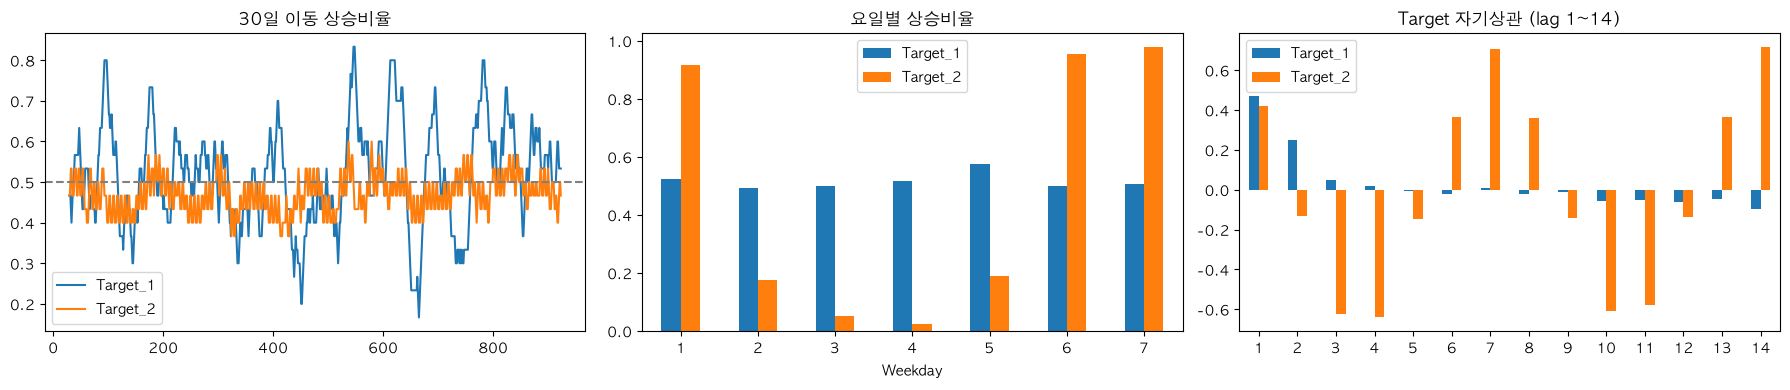

Target_1 요일만 사용한 Valid AUC: 0.484
Target_2 요일만 사용한 Valid AUC: 0.926


In [7]:
fig, ax = plt.subplots(1, 3, figsize=(18, 4))
for t in TARGETS:
    train[t].rolling(30).mean().plot(ax=ax[0], label=t)
ax[0].axhline(0.5, ls='--', c='gray'); ax[0].set_title('30일 이동 상승비율'); ax[0].legend()
train.groupby('Weekday')[TARGETS].mean().plot.bar(ax=ax[1], title='요일별 상승비율', rot=0)
pd.DataFrame({t: [train[t].autocorr(k) for k in range(1, 15)] for t in TARGETS},
             index=range(1, 15)).plot.bar(ax=ax[2], title='Target 자기상관 (lag 1~14)', rot=0)
plt.tight_layout(); plt.show()

# 요일만으로 얻는 AUC (앞 70% 요일별 평균 → 뒤 30% 예측)
s = int(len(train) * 0.7)
for t in TARGETS:
    m = train[:s].groupby('Weekday')[t].mean()
    print(t, '요일만 사용한 Valid AUC:', round(roc_auc_score(train[s:][t], train[s:].Weekday.map(m)), 3))

#### 👀 그림 읽는 법 — 문제 자체의 성질 3가지
| 그림 | 보는 법 | 지금 결과 → 의미 |
| --- | --- | --- |
| 왼쪽: 30일 이동 상승비율 | 0.5 근처에서 잔잔하면 일정한 문제, 크게 출렁이면 **시기마다 성격이 다름** | T1(파랑) 0.2~0.8 큰 파도 → 상승장·하락장이 몇 달씩 이어짐. 과거에 맞던 규칙이 미래에 안 맞을 위험 = **과적합 주의**. T2(주황)는 0.4~0.6으로 안정 |
| 가운데: 요일별 상승비율 | 막대 높이가 요일마다 다르면 요일이 Target을 설명 | T1은 모든 요일 ≈0.5 → 요일 무관 (요일만 AUC 0.48). **T2는 1·6·7 ≈0.95, 3·4 ≈0.03, 2·5 ≈0.18** → 요일만 알아도 Valid AUC **0.926** |
| 오른쪽: 자기상관 | 막대가 크면 'k일 전 Target과 오늘 Target이 닮음' | T2는 7·14일 +0.7, 3·4·10·11일 −0.6 → **정확히 7일 주기**. T1의 lag1(0.47)·lag2(0.25)는 D+3 구간이 이웃 날과 겹쳐서 생긴 것 |

⚠️ 자기상관이 높아도 **과거 Target을 피처로 쓰면 안 된다**. 어제의 Target(어제 기준 D+3 = 내일모레 가격)은 오늘 아직 모르는 값이다.

**→ 결론**: T2 = "요일 문제", T1 = "요일 무관 + 시기마다 출렁이는 어려운 문제".

#### 📅 `Weekday` 번호의 정체와 '주말 0' 효과 (설명서에 없는 추론)
**1 = 일요일, 2 = 월요일, … , 7 = 토요일** (엑셀 `WEEKDAY()` 기본값과 같은 체계)

**근거**: 주식·환율 시장은 주말에 쉬므로, 휴장일에는 금융 값이 전날 값 그대로 복사된다. 요일별로 '전일 값과 같은 비율'을 세면 다음과 같다.

| 금융 변수 | 요일 1·7 | 요일 2~6 |
| --- | --- | --- |
| 18개 중 **16개** (미국 지수·국제유가·금리·원자재·환율) | **100%** (Train·Public·Private 모두) | 2~16% (공휴일로 추정) |
| 국내 유가 2개 (`FI_Gasoline`, `FI_Diesel`) | 0~7% (주유소 가격이라 주말에도 바뀜) | — |

→ 요일 1·7 = 휴장일 = **일·토**. 설명서에는 요일 정의가 없으므로 이는 **데이터에서 추론한 것**이다. 같은 패턴이 Test 파일에서도 그대로 나타나므로 Test에도 그대로 적용된다.

**요일 이름으로 다시 읽은 T2**: 일·금·토(→ 3일 뒤 수·월·화) 상승 ≈ 0.95, 화·수(→ 금·토) 하락 → "주말에서 평일로 넘어가면 쇼핑 클릭이 늘어난다".

**⚠️ 금융 변화율의 '요일 대리' 효과**: 국내 유가를 제외한 금융 변수는 주말에 값이 멈추므로, `chg1` 같은 전일 대비 변화율이 **주말에는 항상 0**이 된다.
- 그래서 금융 변화율이 "오늘이 주말인가"를 간접적으로 알려준다. T2(요일로 결정됨)에서 금융 `chg` 변수가 약한 신호(|AUC−0.5| ≈ 0.09)를 보이는 것은 대부분 이 **요일 대리 효과**로 본다.
- T1의 금융 신호(미국 지수 `chg1`)는 **평일 기준으로 해석**하는 것이 정확하다. 주말 행에서는 이 피처가 정보를 주지 못한다(주말 보정은 train.ipynb 백로그 7, E8 후보).

## 2. 변수군 프로파일 — 전처리 방향 (추세·왜도·0 비율)

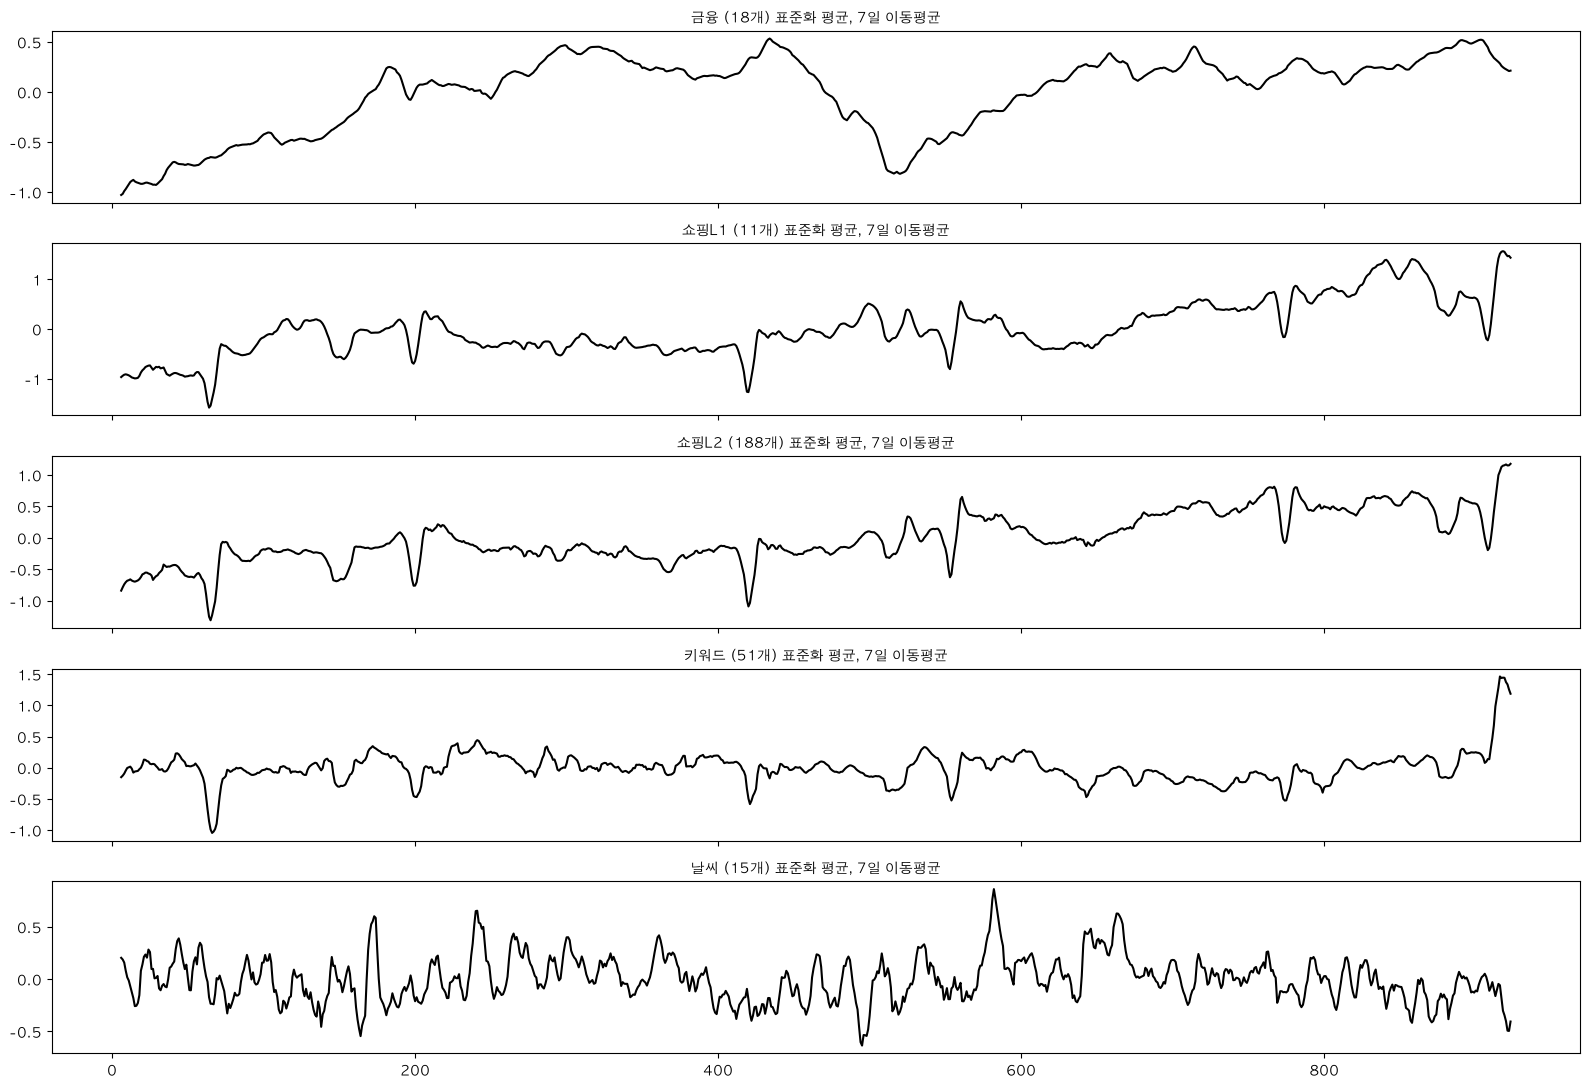

,skew,zero_ratio,lag1_autocorr
group,,,
금융,0.24,0.0,0.99
날씨,0.80,0.0,0.61
쇼핑L1,0.39,0.0,0.89
쇼핑L2,0.78,0.0,0.89
키워드,1.62,0.0,0.58


In [8]:
fig, axes = plt.subplots(len(GROUP), 1, figsize=(16, 11), sharex=True)
for ax, name in zip(axes, GROUP.values()):
    cols = grp[grp == name].index
    z = (X[cols] - X[cols].mean()) / X[cols].std()
    z.mean(axis=1).rolling(7).mean().plot(ax=ax, c='k')
    ax.set_title(f'{name} ({len(cols)}개) 표준화 평균, 7일 이동평균', fontsize=10)
plt.tight_layout(); plt.show()

prof = pd.DataFrame({'group': grp, 'skew': X.skew(), 'zero_ratio': (X == 0).mean(),
                     'lag1_autocorr': X.apply(lambda c: c.autocorr(1))})
prof.groupby('group')[['skew', 'zero_ratio', 'lag1_autocorr']].median().round(2)

#### 🧭 이 셀이 하는 일
군마다 변수를 **표준화(평균 0, 표준편차 1)한 뒤 평균**해 군 전체 흐름을 선 하나로 그린다. 아래 표는 군별 중앙값이다.
- `skew`(왜도): 한쪽 꼬리가 긴 정도. 1이 넘으면 가끔 튀는 큰 값이 있다는 뜻
- `zero_ratio`: 0인 비율
- `lag1_autocorr`: 어제 값과 오늘 값이 얼마나 닮았나

#### 👀 그림 읽는 법
선이 **한 방향으로 계속 움직이면 '추세'** 다. 추세가 있는 변수를 원값 그대로 넣으면, 모델은 Train 시기의 값 범위로 규칙을 배우는데 Test(Train 이후 기간)는 처음 보는 범위가 되어 규칙이 맞지 않는다.

| 군 | 지금 결과 | 방향 |
| --- | --- | --- |
| 금융 | −1 → +0.5로 크게 이동, 자기상관 0.99 (어제 값 ≈ 오늘 값) | 원값 대신 **변화율** |
| 쇼핑L1·L2 | 후반으로 갈수록 상승, 마지막 구간 급등 | 원값 대신 **비율(평소 대비)** |
| 키워드 | 대체로 평평하지만 왜도 1.62 (가끔 폭증) | 비율 변환으로 완화 |
| 날씨 | 계절 반복, 추세 없음 | 그대로 가능 (단 신호 약함, §3) |

`zero_ratio`는 중앙값이라 0으로 보이지만 일부 쇼핑 변수에 0이 있다. 비율을 계산할 때 0으로 나누면 무한대가 되므로 **0을 결측으로 바꿔** 처리한다.

## 3. 변환별 단일 변수 신호 (AUC)

같은 변수도 **어떤 형태로 넣느냐**에 따라 신호가 달라진다. 모두 과거 값만 사용한다.

| 변환 | 의미 |
| --- | --- |
| level | 원값 |
| chg1 / chg3 / chg7 | 1·3·7일 전 대비 변화율 (Lag 파생) |
| z20 | 최근 20일 평균 대비 위치 (Rolling 파생) |
| sameWD | 지난 4주 **같은 요일** 평균 대비 비율 (주간 계절성 제거) |

In [9]:
TRANSFORMS = {
    'level':  lambda D: D,
    'chg1':   lambda D: D.pct_change(1, fill_method=None),
    'chg3':   lambda D: D.pct_change(3, fill_method=None),
    'chg7':   lambda D: D.pct_change(7, fill_method=None),
    'z20':    lambda D: (D - D.rolling(20).mean()) / D.rolling(20).std(),
    'sameWD': lambda D: D / (sum(D.shift(7 * k) for k in range(1, 5)) / 4).replace(0, np.nan),
}
TF = {k: f(X).replace([np.inf, -np.inf], np.nan) for k, f in TRANSFORMS.items()}

def auc(x, y):
    m = x.notna()
    return roc_auc_score(y[m], x[m]) if m.sum() > 30 and y[m].nunique() == 2 else np.nan

half = len(train) // 2
rows = []
for tf, D in TF.items():
    for t in TARGETS:
        y = train[t]
        for c in FEATS:
            x = D[c]
            rows.append((c, grp[c], tf, t, auc(x, y), auc(x[:half], y[:half]), auc(x[half:], y[half:])))
res = pd.DataFrame(rows, columns=['feat', 'group', 'tf', 'target', 'auc', 'auc_h1', 'auc_h2'])
same_dir = np.sign(res.auc_h1 - 0.5) == np.sign(res.auc_h2 - 0.5)
# stable: 앞/뒤 절반 방향이 같을 때 둘 중 약한 쪽 신호 (방향이 바뀌면 0)
res['stable'] = np.where(same_dir, np.minimum((res.auc_h1 - 0.5).abs(), (res.auc_h2 - 0.5).abs()), 0)
res.sort_values('stable', ascending=False).groupby('target').head(5)

,feat,group,tf,target,auc,auc_h1,auc_h2,stable
1599,SH2_쇼핑2_식품_축산,쇼핑L2,chg3,Target_2,0.068046,0.071886,0.063799,0.428114
1645,SH2_쇼핑2_생활건강_화방용품,쇼핑L2,chg3,Target_2,0.070702,0.072135,0.069394,0.427865
1643,SH2_쇼핑2_생활건강_공구,쇼핑L2,chg3,Target_2,0.068815,0.074513,0.062166,0.425487
1447,KE_암보험,키워드,chg3,Target_2,0.071285,0.076584,0.064944,0.423416
1471,KE_재택근무,키워드,chg3,Target_2,0.074780,0.072500,0.076754,0.423246
568,FI_Sp500,금융,chg1,Target_1,0.597684,0.594094,0.601099,0.094094
567,FI_Dow,금융,chg1,Target_1,0.597216,0.603373,0.592233,0.092233
1134,FI_Sp500,금융,chg3,Target_1,0.593919,0.598893,0.588738,0.088738
3053,SH2_쇼핑2_스포츠레저_수련용품,쇼핑L2,sameWD,Target_1,0.596826,0.601635,0.586298,0.086298
3076,SH2_쇼핑2_생활건강_재활운동용품,쇼핑L2,sameWD,Target_1,0.597669,0.586089,0.605800,0.086089


#### 🧭 이 셀이 하는 일 (EDA의 핵심 계산)
287개 변수 × 6개 변환 × 2개 Target ≈ **3,400개 조합마다 AUC를 계산**한다. 같은 계산을 Train 앞 절반·뒤 절반에서 따로 해 `stable` 점수를 매긴다. 결과 표 `res`가 이후 §3-1~§7 그림의 재료이고, 출력은 Target별 stable 상위 5개다.

#### 👀 표 읽는 법
- T2 상위 5개는 AUC가 **0.07**이다. 낮아 보이지만 0.5에서 가장 멀리 떨어진 값이라 **거꾸로 된 아주 강한 신호**다. "3일 전보다 클릭이 늘었으면(chg3↑) 3일 뒤 하락"이라는 뜻이다.
- T1 상위는 S&P500·Dow `chg1` AUC **0.60**이다. 한 변수로는 이 정도가 최대다.
- ❓ 쇼핑 '축산', '화방용품', '공구'가 왜 건강식품 지수를 이렇게 잘 맞힐까? → §3-1, §4, §5에서 **요일 때문**임을 확인한다.

### 3-1. 변수군 × 변환 히트맵 — 어디에 신호가 모여 있나
값 = 해당 칸 변수들 중 **안정 신호(stable > 0.03)** 를 가진 비율. 절반 구간 표본(약 460개)에서 AUC 잡음은 대략 ±0.03 수준이라 이를 기준으로 삼는다.

In [ ]:
fig, ax = plt.subplots(1, 2, figsize=(16, 4.5))
for a, t in zip(ax, TARGETS):
    piv = res[res.target == t].assign(hit=lambda d: d.stable > 0.03).pivot_table(index='group', columns='tf', values='hit', aggfunc='mean')
    sns.heatmap(piv[list(TRANSFORMS)], annot=True, fmt='.0%', cmap='Blues', vmin=0, vmax=0.6, ax=a)
    a.set_title(f'{t}: 안정 신호 변수 비율')
plt.tight_layout(); plt.show()

#### 👀 그림 읽는 법 — "어떤 형태로 넣어야 신호가 살아나나" 지도
칸 하나 = 변수군 × 변환이다. 숫자는 그 칸의 변수 중 **안정 신호(stable > 0.03)를 가진 비율**이고, 진할수록 신호가 많다. 기준을 0.03으로 잡은 이유는 절반 구간(약 460일)에서 우연히 생기는 AUC 오차가 ±0.03 정도이기 때문이다.

| | 지금 결과 | 의미 |
| --- | --- | --- |
| T1 | 금융은 `chg3`(39%)·`chg1`(28%)에서만, 쇼핑L2·키워드는 `sameWD`(54%·45%)·`z20`에서 진함 | 같은 변수라도 **원값보다 '변화'·'평소 대비' 형태로 넣어야** 신호가 생김 |
| T2 | 쇼핑·키워드가 거의 모든 변환에서 80~100% | 너무 많은 변수가 신호 = **공통 원인 하나**가 있다는 의심 |
| T2 (핵심 단서) | 같은 요일끼리 비교하는 `chg7`·`sameWD` 열만 비율이 뚝 떨어짐 (쇼핑L1 0%) | **요일 효과를 지우면 신호가 사라진다** → 신호의 정체는 요일 |

### 3-2. 앞/뒤 절반 AUC 비교 — 대각선 위 = 시간이 지나도 유지되는 신호

In [ ]:
fig, ax = plt.subplots(1, 2, figsize=(16, 6.5))
for a, t in zip(ax, TARGETS):
    d = res[res.target == t]
    sns.scatterplot(data=d, x='auc_h1', y='auc_h2', hue='group', s=12, alpha=.6, ax=a)
    a.axhline(.5, c='gray', lw=.8); a.axvline(.5, c='gray', lw=.8); a.plot([.2, .8], [.2, .8], 'k--', lw=.8)
    a.set_title(f'{t}: 앞 절반 vs 뒤 절반 AUC  (상관 {d.auc_h1.corr(d.auc_h2):.2f})')
plt.tight_layout(); plt.show()

#### 👀 그림 읽는 법 — "이 신호, 미래에도 통할까?"
점 하나 = 변수×변환 조합 하나다. x축은 **앞 절반** AUC, y축은 **뒤 절반** AUC다.
- **점선(대각선) 위에 줄지어 있으면** 두 시기에 같은 신호가 나온다는 뜻이라 믿을 만하다.
- 가운데 (0.5, 0.5)에 **둥글게 뭉쳐 있으면** 대부분 잡음이다.
- 그래프 제목의 '상관'은 앞뒤가 얼마나 일치하는지를 한 숫자로 나타낸 것이다.

| | 지금 결과 | 의미 |
| --- | --- | --- |
| T1 | 0.4~0.6 둥근 덩어리, **상관 0.39** | 앞 절반에서 좋던 변수가 뒤 절반에서도 좋을 보장이 거의 없음. 변수를 많이 넣으면 잡음을 외워 **과적합** → 변수 적게, 정규화 강하게 |
| T2 | 대각선 위에 일렬, **상관 0.97** | 신호가 시간이 지나도 단단함 |

※ 이 그림과 아래 막대 그림은 군별 색 배정이 다르다. 색은 각 그림의 범례로 확인한다.

### 3-3. Target별 안정 신호 상위 20 (막대 = AUC-0.5, 음수는 반대 방향)

In [ ]:
pal = dict(zip(GROUP.values(), sns.color_palette('tab10')))
fig, ax = plt.subplots(1, 2, figsize=(18, 7))
for a, t in zip(ax, TARGETS):
    top = res[res.target == t].nlargest(20, 'stable').iloc[::-1]
    a.barh(top.feat + ' | ' + top.tf, top.auc - .5, color=top.group.map(pal))
    a.axvline(0, c='k', lw=.8); a.set_title(f'{t} 안정 신호 Top 20'); a.tick_params(axis='y', labelsize=8)
ax[1].legend(handles=[plt.Rectangle((0, 0), 1, 1, color=c) for c in pal.values()], labels=list(pal), loc='lower right')
plt.tight_layout(); plt.show()

#### 👀 그림 읽는 법
막대 하나 = 상위 신호 변수다(이름 = `변수 | 변환`). 길이는 AUC−0.5로, **오른쪽이면 값이 클수록 상승, 왼쪽이면 값이 클수록 하락**이다. 색은 변수군이다.
- **T1**: 맨 위가 금융(파랑) `FI_Sp500/Dow | chg1` ≈ +0.10이고, 나머지는 쇼핑L2(초록) `sameWD` ≈ +0.08~0.10이다. 신호원은 크게 두 종류다: ① 직전 미국장 등락, ② 소비 관심도가 평소보다 높은가.
- **T2**: 20개 전부 −0.42 근처, 대부분 `chg3`이다. 축산·공구·암보험처럼 품목은 제각각인데 세기가 똑같다는 것은 **품목 정보가 아니라 같은 하나(요일)를 반복해서 말하고 있다**는 신호다.

## 4. Target_2 심층 — 요일 구조와 애매한 요일(2·5)

Target_2는 요일이 대부분을 설명한다. 남은 점수는 **요일 2·5에서 상승/하락을 가르는 것**에 달려 있다.

In [ ]:
sh1 = grp[grp == '쇼핑L1'].index
wd = X[sh1].groupby(train.Weekday).mean()
wd = wd / wd.mean()                                   # 컬럼별 평균 대비
wd['▶ Target_2 상승비율'] = train.groupby('Weekday').Target_2.mean()
plt.figure(figsize=(14, 4))
sns.heatmap(wd.T, annot=True, fmt='.2f', cmap='RdBu_r', center=1)
plt.title('쇼핑L1 클릭량의 요일 패턴 (평균=1) vs Target_2'); plt.show()

amb = train.Weekday.isin([2, 5]).values
y2, h = train.Target_2[amb], amb.sum() // 2
rows = []
for tf, D in TF.items():
    for c in FEATS:
        x = D[c][amb]
        rows.append((c, grp[c], tf, auc(x, y2), auc(x[:h], y2[:h]), auc(x[h:], y2[h:])))
amb_res = pd.DataFrame(rows, columns=['feat', 'group', 'tf', 'auc', 'auc_h1', 'auc_h2'])
amb_res['stable'] = np.where(np.sign(amb_res.auc_h1 - .5) == np.sign(amb_res.auc_h2 - .5),
                             np.minimum((amb_res.auc_h1 - .5).abs(), (amb_res.auc_h2 - .5).abs()), 0)
top = amb_res.nlargest(15, 'stable').iloc[::-1]
plt.figure(figsize=(10, 6))
plt.barh(top.feat + ' | ' + top.tf, top.auc - .5, color=top.group.map(pal)); plt.axvline(0, c='k', lw=.8)
plt.title(f'요일 2·5에서만 본 Target_2 신호 Top 15 (n={amb.sum()})'); plt.yticks(fontsize=8); plt.tight_layout(); plt.show()
amb_res.groupby(['group', 'tf']).stable.apply(lambda s: (s > .05).mean()).unstack().round(2)

#### 👀 첫 번째 그림 (히트맵) 읽는 법 — T2가 요일로 결정되는 이유
행은 쇼핑L1 카테고리, 열은 요일이다. 값은 그 요일 평균 클릭량 ÷ 전체 평균이라 **1보다 크면(빨강) 그 요일에 클릭이 많다**. 맨 아래 줄은 그 요일의 Target_2 상승비율이다.

**식품 행으로 "오늘 요일 → 3일 뒤 요일"을 따라가 보면**:
| 오늘 요일 | 오늘 클릭 | 3일 뒤 요일 | 3일 뒤 클릭 | 변화 | Target_2 상승비율 |
| --- | --- | --- | --- | --- | --- |
| 1 | 0.91 | 4 | 1.13 | ↑ | **0.92** |
| 4 | 1.13 | 7 | 0.69 | ↓↓ | **0.02** |
| 6 | 0.84 | 2 | 1.21 | ↑↑ | **0.95** |
| 2 | 1.21 | 5 | 1.00 | ↓ | 0.17 |
| 5 | 1.00 | 1 | 0.91 | 약간↓ | 0.19 |

→ 건강식품 지수는 사실상 **"3일 뒤 요일이 오늘 요일보다 클릭이 많은 날인가"** 를 따라간다. 이 관찰이 §8 파생변수의 출발점이다.

#### 👀 두 번째 그림 (막대) — 애매한 요일 2·5에서 추가 신호 찾기
요일 2·5인 날(264일)만 모아 AUC를 다시 계산했다. 요일 효과가 거의 고정된 상태라 **요일 말고 남은 신호**만 보인다.
- 대부분 **왼쪽(−)이고 `z20`**: "최근 20일 평균보다 높으면 3일 뒤 하락", 즉 **평균회귀**다.
- 보험 키워드(암보험·보험·종신보험)와 디지털가전 품목이 많다.

아래 표는 변수군×변환별로 요일 2·5에서 stable > 0.05인 비율이다. 쇼핑L2·키워드에 보강 재료가 남아 있다. 다만 요일 2와 5를 섞어 계산했으므로 두 요일 사이의 차이도 일부 섞여 있다.

## 5. Lag 탐색 — 상위 변수의 신호가 며칠 전 값에서 가장 강한가

In [ ]:
fig, ax = plt.subplots(1, 2, figsize=(18, 5))
for a, t in zip(ax, TARGETS):
    top = res[res.target == t].nlargest(40, 'stable').drop_duplicates('feat').head(10)
    lag_auc = pd.DataFrame({f'{r.feat}|{r.tf}': [auc(TF[r.tf][r.feat].shift(L), train[t]) - .5 for L in range(0, 11)]
                            for r in top.itertuples()}, index=range(0, 11)).T
    sns.heatmap(lag_auc, annot=True, fmt='.2f', cmap='RdBu_r', center=0, ax=a, annot_kws={'size': 7})
    a.set_xlabel('추가 lag (일)'); a.set_title(f'{t}: lag별 AUC-0.5'); a.tick_params(axis='y', labelsize=7)
plt.tight_layout(); plt.show()

#### 👀 그림 읽는 법 — "며칠 전 값까지 유효한가"
행은 상위 신호 변수, 열은 **추가로 미룬 날 수**다(0 = 그대로, 3 = 3일 더 전의 값을 사용). 색은 AUC−0.5로 빨강 = 상승 신호, 파랑 = 하락 신호다.

| | 지금 결과 | 의미 |
| --- | --- | --- |
| T1 금융 `chg1` | 0일 0.10 → 1일만 밀려도 0.02~0.03 | **가장 최근 미국장 등락만** 의미 있음 → 긴 lag 피처 불필요 |
| T1 쇼핑 `sameWD` | 0.10 → 5~7일까지 천천히 감소 | 며칠씩 이어지는 **느린 흐름** (소비 관심도 공통 요인) |
| T2 전부 | −0.43 → 0 → +0.39 → … → 7일 뒤 다시 −0.39 | 행마다 **무늬가 똑같고 7일 주기로 부호가 바뀜** → 변수 자체의 정보가 아니라 "며칠 전이냐 = 무슨 요일이냐"만 반영 |

## 6. 중복(다중공선성) 확인 — 상위 신호 변수끼리 같은 정보인가

In [ ]:
fig, ax = plt.subplots(1, 2, figsize=(20, 8))
for a, t in zip(ax, TARGETS):
    top = res[res.target == t].nlargest(20, 'stable')
    M = pd.DataFrame({f'{r.feat}|{r.tf}': TF[r.tf][r.feat] for r in top.itertuples()})
    sns.heatmap(M.corr(), cmap='RdBu_r', center=0, vmin=-1, vmax=1, ax=a, xticklabels=False)
    a.set_title(f'{t}: 상위 20 신호 변수 간 상관'); a.tick_params(axis='y', labelsize=7)
plt.tight_layout(); plt.show()

#### 👀 그림 읽는 법 — "상위 변수들이 서로 다른 정보인가"
상위 20개 변수끼리의 상관계수다. **진한 빨강은 거의 같은 정보**, 흰색은 서로 무관하다는 뜻이다. 같은 정보를 여러 개 넣어도 모델 성능은 오르지 않고 잡음과 과적합 위험만 늘어난다.
- **T1**: 금융 3개(왼쪽 위)끼리 진한 빨강(S&P500·Dow는 같이 움직임), 쇼핑 `sameWD`끼리 0.5~0.8 덩어리, **금융과 쇼핑 사이는 흰색**. 즉 서로 독립된 정보원 2개다. 쇼핑은 개별 변수를 넣지 않고 군별 중앙값 하나로 압축한다(train.ipynb `samewd_grp`).
- **T2**: 거의 전체가 빨강이다. 20개가 사실상 정보 1개(요일)라서 대량 투입할 이유가 없다.

## 7. 요약 표 — 변수군별 최고 신호와 안정 변수 수

In [ ]:
summary = (res.assign(hit=res.stable > .03)
              .groupby(['target', 'group'])
              .agg(안정변수수=('hit', 'sum'), 최대stable=('stable', 'max'), 최대신호=('auc', lambda s: (s - .5).abs().max()))
              .round(3))
summary

#### 👀 표 읽는 법
- `안정변수수`: stable > 0.03인 조합 수
- `최대stable`: 가장 믿을 만한 신호의 세기
- `최대신호`: 전체 기간 |AUC−0.5| 최댓값

**T1은 어느 군이든 최대 신호가 0.10 이하**다. 변수 하나로는 AUC 0.6이 한계이므로, 모델 목표도 0.6대가 현실적이다. T2는 0.43이지만 앞에서 본 대로 대부분 요일 정보다. 날씨는 두 Target 모두 가장 약하다.

## 8. 파생변수 검증 — Target_2용 "지난주 D+3 요일 값 / 오늘 값"

4번 히트맵에서 Target_2 ≈ "식품·생활건강 클릭량이 3일 뒤 오늘보다 높은가"로 보인다.
3일 뒤 값은 모르지만 **같은 요일의 지난 값(오늘 기준 4·11·18·25일 전)** 은 이미 알고 있다 → Leakage 없는 예측치.

In [ ]:
y2, amb2, s = train.Target_2, train.Weekday.isin([2, 5]), int(len(train) * 0.7)
def d3_ratio(x, weeks=4):            # 지난 n주 'D+3 요일' 평균 / 오늘 값  (과거 값만 사용)
    return (sum(x.shift(4 + 7 * k) for k in range(weeks)) / weeks / x.replace(0, np.nan))

rows = []
for name, x in {'식품': X['SH1_쇼핑1_식품'], '생활건강': X['SH1_쇼핑1_생활건강'],
                '식품+생활건강': X[['SH1_쇼핑1_식품', 'SH1_쇼핑1_생활건강']].mean(axis=1)}.items():
    for w in (1, 4):
        f = d3_ratio(x, w); m = f.notna()
        rows.append((name, f'{w}주', auc(f, y2), auc(f[amb2], y2[amb2]), auc(f[s:], y2[s:])))
cmp = pd.DataFrame(rows, columns=['기준변수', '평균기간', '전체 AUC', '요일2·5 AUC', '뒤30% AUC'])
wd_map = train[:s].groupby('Weekday').Target_2.mean()
cmp.loc[len(cmp)] = ['(비교) 요일만', '-', np.nan, np.nan, roc_auc_score(y2[s:], train.Weekday[s:].map(wd_map))]
cmp.round(3)

#### 🧭 이 셀이 하는 일 — 요일 구조를 '합법적으로' 피처로 만들기
§4에서 T2 ≈ "3일 뒤 클릭이 오늘보다 많은가"였다. 3일 뒤 값은 아직 모르지만, **지난 몇 주 동안 '3일 뒤와 같은 요일'의 값은 이미 알고 있다**.
`d3_ratio` = 지난 n주의 4·11·18·25일 전 값(= 3일 뒤와 같은 요일) 평균 ÷ 오늘 값
→ 1보다 크면 "평소 패턴대로라면 3일 뒤 클릭이 늘어난다"는 예측이 된다. **과거 값만 쓰므로 Leakage가 없다**.

#### 👀 표 읽는 법
| 열 | 의미 | 지금 결과 |
| --- | --- | --- |
| 전체 AUC | Train 전체에서 단일 변수 성능 | 0.93~0.95 |
| 요일2·5 AUC | 애매한 요일 안에서도 가르나 | 0.71~0.74 → **요일만으로는 못 가르는 날도 일부 맞힘** |
| 뒤30% AUC | 요일만 사용(0.926)과 같은 구간에서 비교 | **식품+생활건강 4주 0.957 > 요일만 0.926** → 요일 이상의 정보가 있음 |

1주와 4주를 비교하면 4주 평균이 대체로 낫다. 여러 주를 평균하면 한 주의 우연한 튐이 줄어들기 때문이다.

## 9. 인사이트 → 파생변수·전처리·Selection 방향

> 수치는 Train 단일 변수 기준이다. 실제 채택은 다음 단계 **시계열 CV(갈래 ①)** 로 확정한다.

### Target_2 (건강식품) — "요일 + 주간 패턴 비교" 문제
| 관찰 (그림) | 해석 | 방향 |
| --- | --- | --- |
| 요일별 상승비율 1·6·7 ≈ 0.95, 3·4 ≈ 0.03 (§1) | Target이 주간 주기를 그대로 따름 | `Weekday` one-hot + **D+3 요일** 피처 |
| 쇼핑/키워드 `chg3` 수백 개가 AUC 0.07 수준 (§3-3), lag 히트맵이 7일 주기로 부호 반전 (§5) | 대부분 **요일을 다시 표현한 것**일 뿐 새 정보가 아님. 서로 상관도 높음 (§6) | 상위 `chg3`를 대량 투입하지 말 것. **요일을 통제한 뒤** 신호로 선택 |
| 요일 2·5에서도 보험 키워드·디지털가전 `z20`이 음의 신호 (§4) | 최근 평균보다 높으면 3일 뒤 하락(평균회귀) | 애매한 요일 보강용 `z20` 소수 |
| **지난 4주 D+3 요일 평균 / 오늘** 단일 변수 뒤30% AUC ≈ 0.96 (요일만 0.93) (§8) | Target 구조를 직접 모사하는 핵심 파생변수 | **최우선 채택**. 식품·생활건강 및 관련 SH2 항목으로 확장 |

### Target_1 (KOSPI) — 신호 약함, 안정성 중심
| 관찰 (그림) | 해석 | 방향 |
| --- | --- | --- |
| 앞/뒤 절반 AUC 상관 0.39 (§3-2) | 대부분 변수 신호가 잡음 수준 | **강한 Selection + 강한 정규화** |
| 미국 지수(S&P500·Dow) `chg1` AUC ≈ 0.60, lag 1만 밀려도 0.02로 소멸 (§5) | 직전 미국장 등락만 유효(미국장이 한국장보다 늦게 마감) | `FI_Sp500/Dow/Nasdaq chg1` 유지, 긴 lag 불필요 |
| 쇼핑/키워드 `sameWD` 다수가 +0.08~0.10, 서로 강하게 상관 (§6), 금융과는 무상관 | 하나의 **공통 요인**(평소 대비 소비 관심도)으로 보임. 원인 불명 → 과적합 위험 | 개별 투입 대신 **변수군 평균 `sameWD` 1~2개로 압축**, CV로 유지 여부 판단 |

### 전처리
| 관찰 | 방향 |
| --- | --- |
| 금융 level은 추세가 크고 lag1 자기상관 0.99 (§2) | level 대신 **변화율** 사용 (시기별 분포 이동 방지) |
| 키워드 왜도 1.6, 쇼핑 0.8 (§2) | 비율·변화율 변환으로 대체로 해소. 트리 모델은 log 불필요, 로지스틱 사용 시 `log1p` |
| 쇼핑 클릭량 0 값 존재 → 비율 계산 시 inf | **0을 NaN 처리 후 Train 기준 대체** |
| `KE_QR체크인` 상수 | 제거 |
| 날씨는 두 Target 모두 신호 약함 (§3-1, §7) | 후순위. CV에서 기여 없으면 제외 |

## 🧭 지금 바라보는 방향 — EDA 가설을 CV로 확인한 결과 (train.ipynb)

EDA 수치는 '변수 하나씩, Train 안에서' 본 것이다. 실제 채택 여부는 **시계열 5-fold CV**(과거로 학습 → 미래로 검증, `train.ipynb`)로 판정했다.

| EDA 가설 | CV 결과 (Valid AUC 평균) | 판정 |
| --- | --- | --- |
| T2: `d3_ratio`가 핵심 (§8) | 앙상블 0.967 → `d3ratio` 빼면 0.959, 요일만 0.937 | ✅ 확인 |
| T2: 요일 2·5 보강용 키워드 `z20` (§4) | 빼도 0.967 → 0.964 (−0.003) | △ 기여 미미 |
| T1: 변수 적게 + 강한 정규화 (§3-2) | 원본 Baseline(565개) 0.522 → EDA 피처셋(82개) 0.597 | ✅ 확인 |
| T1: 쇼핑 `sameWD` 압축 3개 유지 (§6) | 빼면 0.597 → 0.584 | ✅ 유지 |
| T1: 하이퍼파라미터·금융 피처 축소로 더 개선? | RF 깊이·leaf, LR 정규화, 피처 축소 — 최대 개선 +0.008 (잡음 수준), 나머지는 오히려 하락 | ✗ 병목 아님 (신호 자체가 약함) |

**현재 방향**
1. **T2 (0.967)**: 거의 한계에 가깝다. 남은 여지는 **요일 2·5를 더 잘 가르는 것**뿐 → `d3_ratio`를 관련 SH2 세부 품목으로 넓히거나, 2·5 전용 피처를 시도한다.
2. **T1 (≈0.60)**: 더 짜내기보다 **Private 200일에서 무너지지 않게 안정성**을 지킨다(평균−표준편차로 모델 선택, 단순한 모델 선호).
3. 최종 점수는 두 Target의 평균이다. T2를 0.01 올리는 것과 T1을 0.01 올리는 것은 같은 가치지만, 현실적으로 움직일 여지는 둘 다 작다. 따라서 **과적합 없이 지금 수준을 지키는 것**이 우선이다.
